# Grad-CAM for a whole class — Faster R-CNN (ResNet-50 FPN v2) — RGB / YGB / LGB

Same output as the YOLO notebooks, so the **combine notebook** can stack it under YOLOv8n / YOLO12n / YOLO26n:
`FasterRCNN.pkl` bundle + a 2-row figure (`RGB img | YGB img | LGB img | RGB Grad-CAM | YGB Grad-CAM | LGB Grad-CAM`; row 1 = whole image with **all instances of the class**, row 2 = zoom on the highest-scoring object).

* The datasets are read as stored (`SIMD_RGB / SIMD_YGB / SIMD_LGB`): **no colour conversion**, each model gets its own file.
* **Same image, class and focus object as the YOLO runs**: `USE_SAVED_SELECTION = True` reads the `selection.json` written by the YOLO notebook (your YOLO26n run saved image 0796, class *fighter*).
* Weights: `runs_frcnn/SIMD_<c>_FasterRCNN_ce/best.pth` (state dict of `fasterrcnn_resnet50_fpn_v2`, 15 classes + background).

### Why Faster R-CNN needs its own Grad-CAM
YOLO has one head that reads three feature maps; Faster R-CNN is **two-stage**: backbone + FPN → RPN proposes boxes → **RoIAlign** cuts a 7×7 feature patch for each proposal → box head → class scores. So:

1. **Target = class *logit* of the proposals on the object.** The final score is a softmax probability, which saturates: logits `(6, 0)` give `p = 0.9975` and `dp/dlogit = p(1−p) = 0.0025` (almost no gradient), while the logit itself has derivative 1. Using logits keeps the gradient alive.
2. **Which feature map?** RoIAlign gives every proposal to **one** FPN level by its size: `level = ⌊4 + log2(√(w·h)/224)⌋` clipped to 2…5 (FPN outputs `'0'…'3'`, strides 4, 8, 16, 32). Example: a 56×56 proposal → `4 + log2(0.25) = 2` → level `'0'` (stride 4); a 224×224 proposal → 4 → level `'2'` (stride 16). A gradient therefore reaches **only the level(s) the proposals were assigned to**. We compute Grad-CAM on all four levels and **add** the maps (levels that received no gradient add zero).
3. **Coordinates.** The model resizes the image internally (short side 800) and pads it to a multiple of 32. The CAM is cropped to the un-padded area and resized to the same 640×640 frame as the images and boxes. Predicted boxes (original pixels) are scaled by `640/W, 640/H` (example: `W = 1024`, `x = 512` → `x = 320`).

| Concept | DIP theory | Where |
|---|---|---|
| Image = matrix of channels, resize | digital image, bilinear interpolation | `read_image_rgb`, `prepare_input` |
| FPN levels with strides 4–32 | multi-resolution (pyramid) representation | `FPN_LEVELS` |
| CAM maps → image size, heat-map colouring | up-sampling, min–max normalisation, pseudo-colour, alpha blend | `gradcam_once`, `overlay_cam` |
| IoU | region overlap | `iou_xyxy` |
| Clusters of activation | thresholding, connected components, centroid | `cam_metrics` |

## 1. Imports

In [12]:
from pathlib import Path
import json, math, pickle
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)

PyTorch: 2.7.1+cu118 | device: cuda


## 2. Settings

* `RUN_DIRS`: folders searched for the weights (`best.pth`, or `best.pt`). Your project notebook saves to `runs_frcnn`; `runs_frcnn_neutral` is also checked.
* `CAM_MODE`: `"class_gt"` = target uses the proposals that overlap **any GT box of the class**; `"object"` = only the focus object; `"global"` = top-k logits of the class over the whole image.
* `PROP_IOU_THR`: a proposal feeds the target if its IoU with a GT box of the class is at least this value.
* `FPN_LEVELS`: FPN outputs used for the CAM (`'0'`…`'3'` = strides 4, 8, 16, 32).
* `DET_CONF = 0.5` is the score threshold used in your Faster R-CNN evaluation (YOLO notebooks used 0.25).
* If your 6 GB GPU runs out of memory during Grad-CAM, the code automatically repeats that step on the CPU.

In [13]:
# ================= USER SETTINGS =================
MODEL_TAG    = "FasterRCNN"                 # bundle file = FasterRCNN.pkl (the combine notebook expects this name)
DATASET_NAME = "SIMD"                       # "SIMD" | "SSL"
PROJECT_ROOT = Path(r"C:\Users\DELL\Desktop\c")
SPLIT        = "test"
IMBALANCE_MODE = "ce"
RUN_DIRS     = [PROJECT_ROOT / "runs_frcnn_neutral"]    # searched in this order
MIN_SIZE, MAX_SIZE = 800, 1333              # same as training

DATASET_CLASSES = {
    "SSL":  ['airplane', 'boat', 'car', 'ship'],
    "SIMD": ['car','truck','van','longvehicle','bus','airliner','propeller','trainer',
             'chartered','fighter','other','stairtruck','pushbacktruck','helicopter','boat'],
}
CLASS_NAMES = DATASET_CLASSES[DATASET_NAME]
NUM_CLASSES = len(CLASS_NAMES) + 1          # +1 = background (label 0)

# ---------- selection: same image / class / focus object as the YOLO runs ----------
IMAGE_STEM      = None
MAX_SCAN        = 100
CLASS_ID        = None
FOCUS_GT_INDEX  = None
USE_SAVED_SELECTION = True                  # True -> read selection.json written by the YOLO notebook

# ---------- MANUAL selection (uncomment what you need; only used when USE_SAVED_SELECTION = False) ----------
# class ids SIMD: 0 car, 1 truck, 2 van, 3 longvehicle, 4 bus, 5 airliner, 6 propeller, 7 trainer,
#                 8 chartered, 9 fighter, 10 other, 11 stairtruck, 12 pushbacktruck, 13 helicopter, 14 boat
# class ids SSL : 0 airplane, 1 boat, 2 car, 3 ship
# CLASS_ID       = 9
# IMAGE_STEM     = "0796"
# FOCUS_GT_INDEX = 0

COLORS      = ["RGB", "YGB", "LGB"]
IMAGE_SIZE  = 640                           # figure / box frame (images are squashed to 640x640, as in the YOLO notebooks)

CAM_MODE     = "class_gt"                   # "class_gt" | "object" | "global"
FPN_LEVELS   = ["0", "1", "2", "3"]
TOP_K        = 10                           # top-k proposals per GT object summed into the target
PROP_IOU_THR = 0.4

DET_CONF    = 0.5
MATCH_IOU   = 0.5
CAM_THR, MIN_CLUSTER_PX = 0.5, 64
ZOOM_MIN_HALF = 64

DATASET_DIRS = {c: PROJECT_ROOT / f"{DATASET_NAME}_{c}" for c in COLORS}
OUTPUT_DIR   = PROJECT_ROOT / f"GradCAM_{DATASET_NAME}_class_figures"      # shared by all models
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def find_ckpt(c):
    tried = []
    for d in RUN_DIRS:
        run = d / f"{DATASET_NAME}_{c}_FasterRCNN_{IMBALANCE_MODE}"
        for name in ("best.pth", "best.pt"):
            tried.append(run / name)
            if (run / name).is_file(): return run / name
    raise FileNotFoundError("no Faster R-CNN weights for %s, tried:\n  " % c + "\n  ".join(map(str, tried)))

CHECKPOINTS = {c: find_ckpt(c) for c in COLORS}
for c in COLORS: assert DATASET_DIRS[c].is_dir(), f"missing {DATASET_DIRS[c]}"
print(MODEL_TAG, "| outputs ->", OUTPUT_DIR)
for c in COLORS: print(f"  {c}: {CHECKPOINTS[c]}")

FasterRCNN | outputs -> C:\Users\DELL\Desktop\c\GradCAM_SIMD_class_figures
  RGB: C:\Users\DELL\Desktop\c\runs_frcnn_neutral\SIMD_RGB_FasterRCNN_ce\best.pth
  YGB: C:\Users\DELL\Desktop\c\runs_frcnn_neutral\SIMD_YGB_FasterRCNN_ce\best.pth
  LGB: C:\Users\DELL\Desktop\c\runs_frcnn_neutral\SIMD_LGB_FasterRCNN_ce\best.pth


## 3. Images, labels and models

**DIP:** an image is an `H×W×3` matrix. Faster R-CNN is fed the **original-resolution** image scaled to 0–1 (it resizes internally), exactly as in training; for the figure the same file is also resized to 640×640 (bilinear = weighted mean of the 4 nearest pixels).
YOLO label `class cx cy w h` is normalised, so in the 640×640 frame pixels = fraction × 640.

The model is built with `weights=None` (no COCO download needed), the classification head is replaced by a 16-way head (15 classes + background) and your `best.pth` state dict is loaded.

In [14]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def find_split_dir(root, split):
    for p in Path(root).iterdir():
        if p.is_dir() and p.name.lower() == split.lower(): return p
    raise FileNotFoundError(f"No '{split}' folder inside {root}")

SPLIT_DIRS = {c: find_split_dir(DATASET_DIRS[c], SPLIT) for c in COLORS}
IMAGE_MAPS = {c: {p.stem: p for p in (SPLIT_DIRS[c] / "images").iterdir() if p.suffix.lower() in IMG_EXTS} for c in COLORS}
COMMON_STEMS = sorted(set.intersection(*(set(IMAGE_MAPS[c]) for c in COLORS)))
print("images present in RGB, YGB and LGB:", len(COMMON_STEMS))

def read_image_rgb(path):
    return np.array(Image.open(path).convert("RGB"))          # same reader as in training; for YGB/LGB the 3 stored channels are (Y,G,B)/(L,G,B)

def parse_yolo_file(path):
    rows = []
    if Path(path).exists():
        for line in Path(path).read_text().splitlines():
            p = line.split()
            if len(p) >= 5: rows.append([float(v) for v in p[:5]])
    return np.array(rows, dtype=np.float32).reshape(-1, 5)

def yolo_to_xyxy(row, size=IMAGE_SIZE):
    _, cx, cy, w, h = row
    return np.array([(cx-w/2)*size, (cy-h/2)*size, (cx+w/2)*size, (cy+h/2)*size], dtype=np.float32)

def load_gt(stem):
    return parse_yolo_file(SPLIT_DIRS["RGB"] / "labels" / f"{stem}.txt")

def prepare_input(img_rgb_uint8):
    # 640x640 uint8 version for the figure (the detector itself gets the full-resolution image)
    return cv2.resize(img_rgb_uint8, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR), None

def to_tensor(img_u8, device):
    return torch.from_numpy(img_u8).permute(2, 0, 1).float().div(255.0).to(device)

def build_model():
    m = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, min_size=MIN_SIZE, max_size=MAX_SIZE,
                                   box_score_thresh=0.001, box_detections_per_img=300)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, NUM_CLASSES)
    return m

models = {}
for c in COLORS:
    m = build_model()
    ck = torch.load(CHECKPOINTS[c], map_location="cpu", weights_only=True)
    m.load_state_dict(ck["model"] if isinstance(ck, dict) and "model" in ck else ck)
    models[c] = m.to(DEVICE).eval()
    print(f"loaded {c}")

images present in RGB, YGB and LGB: 500
loaded RGB
loaded YGB
loaded LGB


## 4. Boxes, IoU, detections

**IoU = overlap area / union area**, `union = areaA + areaB − overlap`. Tiny example: two 10×10 boxes shifted by 5 px → 50 / 150 = **0.333**.

`detect` runs the full model (RPN → RoI heads → per-class NMS) on the original-resolution image, keeps scores ≥ `DET_CONF` and rescales the boxes to the 640×640 frame (`× 640/W`, `× 640/H`). Class ids are `label − 1` (label 0 is background).
`class_only` keeps one class, so **all instances** are returned; `match_class` pairs predictions (highest score first) with GT boxes at IoU ≥ `MATCH_IOU`.

In [15]:
def box_area(b): return max(0.0, float(b[2]-b[0])) * max(0.0, float(b[3]-b[1]))

def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0],b[0]), max(a[1],b[1]), min(a[2],b[2]), min(a[3],b[3])
    inter = max(0.0, ix2-ix1) * max(0.0, iy2-iy1)
    union = box_area(a) + box_area(b) - inter
    return inter/union if union > 0 else 0.0
print("IoU check:", round(iou_xyxy([0,0,10,10],[5,0,15,10]), 3), "(expect 0.333)")

@torch.no_grad()
def detect(color, stem):
    img = read_image_rgb(IMAGE_MAPS[color][stem]); H, W = img.shape[:2]
    out = models[color]([to_tensor(img, DEVICE)])[0]
    b, s, l = out["boxes"].cpu().numpy(), out["scores"].cpu().numpy(), out["labels"].cpu().numpy() - 1
    keep = s >= DET_CONF
    if not keep.any(): return np.zeros((0, 6), np.float32)
    b = b[keep] * np.array([IMAGE_SIZE/W, IMAGE_SIZE/H, IMAGE_SIZE/W, IMAGE_SIZE/H], np.float32)
    return np.concatenate([b, s[keep, None], l[keep, None]], axis=1).astype(np.float32)      # x1,y1,x2,y2,conf,cls (640 frame)

def class_only(dets, cls_id):
    return dets[dets[:, 5] == cls_id] if len(dets) else np.zeros((0, 6), np.float32)

def match_class(gt_boxes, preds, thr=MATCH_IOU):
    best = [max([iou_xyxy(p[:4], g) for p in preds], default=0.0) for g in gt_boxes]
    used, tp, match = set(), 0, {}
    for pi in np.argsort(-preds[:, 4]) if len(preds) else []:
        cand = [(iou_xyxy(preds[pi][:4], g), gi) for gi, g in enumerate(gt_boxes) if gi not in used]
        if cand:
            v, gi = max(cand)
            if v >= thr: used.add(gi); tp += 1; match[gi] = int(pi)
    return tp, best, match

def best_correct_detection(stem, cls_filter=None):
    gt = load_gt(stem); dets = detect("RGB", stem); best = None
    for d in dets:
        if cls_filter is not None and int(d[5]) != cls_filter: continue
        for gi, g in enumerate(gt):
            if int(g[0]) == int(d[5]) and iou_xyxy(d[:4], yolo_to_xyxy(g)) >= MATCH_IOU:
                if best is None or d[4] > best[0]: best = (float(d[4]), int(d[5]), gi)
    return best        # (conf, class_id, gt_index) or None

IoU check: 0.333 (expect 0.333)


## 5. Image, class and focus object

`USE_SAVED_SELECTION = True` loads `selection.json` (written by the YOLO notebook), so Faster R-CNN explains the **same image, class and zoomed object**. If the file does not exist, the notebook selects automatically with the RGB Faster R-CNN (highest-scoring correct prediction) and saves it — in that case run the YOLO notebooks afterwards with `USE_SAVED_SELECTION = True`.

In [16]:
sel_file = OUTPUT_DIR / "selection.json"
if USE_SAVED_SELECTION and sel_file.exists():
    sel = json.loads(sel_file.read_text())
    IMAGE_STEM, CLASS_ID, FOCUS_GT_INDEX = sel["image_stem"], sel["class_id"], sel["focus_gt_index"]
    print("loaded saved selection:", sel)
else:
    if IMAGE_STEM is None:
        scores = []
        for s in COMMON_STEMS[:MAX_SCAN]:
            b = best_correct_detection(s, CLASS_ID)
            if b: scores.append((b[0], s))
        assert scores, "no correct RGB detection found (check CLASS_ID / MAX_SCAN)"
        IMAGE_STEM = max(scores)[1]
        print("auto-selected image:", IMAGE_STEM, "| top score", round(max(scores)[0], 3))
    labels = load_gt(IMAGE_STEM)
    b = best_correct_detection(IMAGE_STEM, CLASS_ID)
    if CLASS_ID is None:
        CLASS_ID = b[1] if b else int(labels[0, 0])
    if FOCUS_GT_INDEX is None:
        FOCUS_GT_INDEX = b[2] if (b and b[1] == CLASS_ID) else int(next(i for i, r in enumerate(labels) if int(r[0]) == CLASS_ID))
    sel_file.write_text(json.dumps(dict(image_stem=IMAGE_STEM, class_id=int(CLASS_ID), focus_gt_index=int(FOCUS_GT_INDEX))))
    print("saved selection ->", sel_file)

labels = load_gt(IMAGE_STEM)
CLS_GT_IDX = [i for i, r in enumerate(labels) if int(r[0]) == CLASS_ID]            # every GT instance of the class
assert FOCUS_GT_INDEX in CLS_GT_IDX, "FOCUS_GT_INDEX must be a GT object of the chosen class"
GT_BOXES   = [yolo_to_xyxy(labels[i]) for i in CLS_GT_IDX]
FOCUS_LOCAL = CLS_GT_IDX.index(FOCUS_GT_INDEX)
FOCUS_BOX  = GT_BOXES[FOCUS_LOCAL]
CLASS_NAME = CLASS_NAMES[CLASS_ID]
print(f"image {IMAGE_STEM} | class {CLASS_ID} ({CLASS_NAME}) | {len(GT_BOXES)} GT instances | focus GT#{FOCUS_GT_INDEX} box {np.round(FOCUS_BOX).astype(int).tolist()}")

IMG_FULL = {c: read_image_rgb(IMAGE_MAPS[c][IMAGE_STEM]) for c in COLORS}          # the stored RGB / YGB / LGB files
INPUT_U8 = {c: prepare_input(IMG_FULL[c])[0] for c in COLORS}                       # 640x640x3 uint8, shown in the figure
ORIG_640 = INPUT_U8["RGB"]

# zoom window around the focus object (same window for all models/rows)
fw, fh = FOCUS_BOX[2] - FOCUS_BOX[0], FOCUS_BOX[3] - FOCUS_BOX[1]
half = int(min(320, max(ZOOM_MIN_HALF, 1.0 * max(fw, fh))))
zcx, zcy = (FOCUS_BOX[0] + FOCUS_BOX[2]) / 2, (FOCUS_BOX[1] + FOCUS_BOX[3]) / 2
zx0 = int(np.clip(zcx - half, 0, IMAGE_SIZE - 2 * half)); zy0 = int(np.clip(zcy - half, 0, IMAGE_SIZE - 2 * half))
ZOOM = (zx0, zy0, zx0 + 2 * half, zy0 + 2 * half)
print("zoom window:", ZOOM)

loaded saved selection: {'image_stem': '0460', 'class_id': 6, 'focus_gt_index': 1}
image 0460 | class 6 (propeller) | 2 GT instances | focus GT#1 box [129, 462, 231, 603]
zoom window: (39, 358, 321, 640)


## 6. Grad-CAM for Faster R-CNN

Steps (`gradcam_once`):
1. `model.transform` resizes/pads the image; `model.backbone` gives the FPN maps `Aᵏ` (levels `'0'`…`'3'`); gradients of every level are retained.
2. `model.rpn` proposes boxes (detached); `box_roi_pool` + `box_head` + `box_predictor` give the **class logits** of every proposal.
3. **Target** = sum of the largest logits of the chosen class among proposals that overlap a GT box of the class (IoU ≥ `PROP_IOU_THR`); fallback: the proposals nearest to the GT centre. Then `target.backward()`.
4. For each level: channel weights `αₖ = mean(∂target/∂Aᵏ)` over space, `CAM = ReLU(Σₖ αₖ·Aᵏ)`. Tiny example: `A¹=2, A²=3, α₁=0.5, α₂=−0.2` → `ReLU(0.4) = 0.4`.
5. Each level's CAM is up-sampled to the padded input size and the four are **summed**; the padding is cropped, the result is resized to 640×640 and min–max normalised `(x−min)/(max−min)` (so the maximum is always 1).

*If the CAM is all zero (all weighted sums negative → ReLU = 0), the code retries with the `global` target.*

In [17]:
def make_target_fn(mode, gt_boxes_640, focus_box_640, cid):
    # fn(class_logits [N, nc+1], proposals [N, 4] in resized-image pixels, (h_r, w_r)) -> scalar to back-propagate
    def fn(logits, props, size):
        h_r, w_r = size
        sx, sy = w_r / IMAGE_SIZE, h_r / IMAGE_SIZE                    # 640 frame -> resized frame
        s_cls = logits[:, cid + 1]                                     # label = class id + 1
        if mode == "global":
            return s_cls.topk(min(TOP_K, s_cls.numel())).values.sum()
        boxes = gt_boxes_640 if mode == "class_gt" else [focus_box_640]
        gts = torch.tensor([[b[0]*sx, b[1]*sy, b[2]*sx, b[3]*sy] for b in boxes], device=props.device, dtype=props.dtype)
        mask = (box_iou(props, gts) >= PROP_IOU_THR).any(dim=1)
        if mask.sum() == 0:                                            # tiny object: take the proposals nearest to each GT centre
            pc = (props[:, :2] + props[:, 2:]) / 2
            gc = (gts[:, :2] + gts[:, 2:]) / 2
            mask = torch.zeros_like(mask)
            for g in gc:
                mask[torch.topk(-torch.hypot(pc[:, 0]-g[0], pc[:, 1]-g[1]), min(TOP_K, len(pc))).indices] = True
        s = s_cls[mask]
        return s.topk(min(TOP_K * len(boxes), s.numel())).values.sum()
    return fn

def gradcam_once(model, img_u8, target_fn, device):
    x = to_tensor(img_u8, device)
    model.eval(); model.zero_grad(set_to_none=True)
    with torch.enable_grad():
        images, _ = model.transform([x])
        images.tensors.requires_grad_(True)
        feats = model.backbone(images.tensors)                         # OrderedDict '0','1','2','3','pool'
        for k in FPN_LEVELS: feats[k].retain_grad()
        props, _ = model.rpn(images, feats)                            # proposals are detached inside the RPN
        bf = model.roi_heads.box_head(model.roi_heads.box_roi_pool(feats, props, images.image_sizes))
        logits, _ = model.roi_heads.box_predictor(bf)
        score = target_fn(logits, props[0], images.image_sizes[0])
        score.backward()
    h_r, w_r = images.image_sizes[0]; Hp, Wp = images.tensors.shape[-2:]
    cam_sum = torch.zeros(Hp, Wp, device=device)
    for k in FPN_LEVELS:
        g = feats[k].grad
        if g is None: continue
        a = feats[k].detach()
        alpha = g.mean(dim=(2, 3), keepdim=True)                       # channel weights = spatial mean of the gradient
        cam = F.relu((alpha * a).sum(dim=1, keepdim=True))             # ReLU(sum_k alpha_k A^k)
        cam_sum += F.interpolate(cam, size=(Hp, Wp), mode="bilinear", align_corners=False)[0, 0]
    cam = cam_sum[:h_r, :w_r].cpu().numpy()                            # remove the padding
    cam = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    del feats, images, props, bf, logits, score
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-12) if cam.max() > 0 else cam

def generate_gradcam(color):
    img = IMG_FULL[color]
    def run(mode):
        fn = make_target_fn(mode, GT_BOXES, FOCUS_BOX, CLASS_ID)
        try:
            return gradcam_once(models[color], img, fn, DEVICE)
        except torch.cuda.OutOfMemoryError:
            print(f"[{color}] CUDA out of memory -> repeating Grad-CAM on the CPU")
            torch.cuda.empty_cache(); models[color].to("cpu")
            try: return gradcam_once(models[color], img, fn, torch.device("cpu"))
            finally: models[color].to(DEVICE); torch.cuda.empty_cache()
    cam = run(CAM_MODE)
    if cam.max() <= 1e-8:
        print(f"[warning] {color}: CAM is all zero with mode '{CAM_MODE}' -> retrying with 'global'")
        cam = run("global")
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return cam

## 7. Class-level metrics (for the caption / table)

| Variable | Meaning | DIP idea |
|---|---|---|
| n_GT, n_pred, TP | instances of the class, predictions of the class, matches at IoU ≥ `MATCH_IOU` | counting |
| mean IoU | mean over the GT instances of their best IoU with a prediction | region overlap |
| focus IoU / conf | IoU and confidence of the prediction matched to the zoomed object | region overlap |
| CAM in GT % | Σ CAM inside the union of all GT boxes / Σ CAM total × 100 | weighted sum over an ROI mask |
| enrichment | (CAM in GT %) / (area share of the GT boxes %): 1 = no better than random | normalised ROI statistic |
| outside clusters | blobs of `CAM ≥ CAM_THR` touching **no** GT box (connected components) | thresholding + connected components |
| weighted distance | Σ(activation·distance)/Σ activation, cluster centroid → nearest GT centre | centroid, Euclidean distance |
| GT brightness, colour variance | mean luma inside the GT boxes; variance of the whole RGB image | mean / variance |

In [18]:
def cam_metrics(cam, gt_boxes, preds, focus_local, scene_rgb_u8, cam_thr=CAM_THR, min_px=MIN_CLUSTER_PX):
    H, W = cam.shape
    gt_mask = np.zeros((H, W), bool); centres = []
    for (x1, y1, x2, y2) in gt_boxes:
        ix1, iy1 = int(np.clip(round(x1), 0, W-1)), int(np.clip(round(y1), 0, H-1))
        ix2, iy2 = int(np.clip(round(x2), ix1+1, W)), int(np.clip(round(y2), iy1+1, H))
        gt_mask[iy1:iy2, ix1:ix2] = True; centres.append(((x1+x2)/2, (y1+y2)/2))
    in_gt = 100.0 * cam[gt_mask].sum() / (cam.sum() + 1e-12)
    share = 100.0 * gt_mask.mean()
    n, lab, stats, cents = cv2.connectedComponentsWithStats((cam >= cam_thr).astype(np.uint8), connectivity=8)
    cl = []
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] < min_px: continue
        comp = lab == k
        if (comp & gt_mask).any(): continue
        d = min(math.hypot(cents[k][0]-cx, cents[k][1]-cy) for cx, cy in centres)
        cl.append((float(cam[comp].sum()), d))
    wd = sum(a*d for a, d in cl) / sum(a for a, _ in cl) if cl else 0.0
    tp, best, match = match_class(gt_boxes, preds)
    fpi = match.get(focus_local)
    if fpi is not None: f_iou, f_conf = iou_xyxy(preds[fpi][:4], gt_boxes[focus_local]), float(preds[fpi][4])
    elif len(preds):                                  # no match: report the same-class prediction closest to the focus object
        j = int(np.argmax([iou_xyxy(p[:4], gt_boxes[focus_local]) for p in preds]))
        f_iou, f_conf = iou_xyxy(preds[j][:4], gt_boxes[focus_local]), float(preds[j][4])
    else: f_iou = f_conf = None
    luma = 0.299*scene_rgb_u8[..., 0] + 0.587*scene_rgb_u8[..., 1] + 0.114*scene_rgb_u8[..., 2]
    return {"n_GT": len(gt_boxes), "n_pred": int(len(preds)), "TP": int(tp),
            "precision": tp/len(preds) if len(preds) else 0.0, "recall": tp/len(gt_boxes),
            "mean_IoU": float(np.mean(best)), "focus_IoU": f_iou, "focus_conf": f_conf,
            "CAM_in_GT_pct": in_gt, "GT_area_share_pct": share, "enrichment": in_gt/share if share > 0 else np.nan,
            "outside_clusters": len(cl), "weighted_distance_px": wd,
            "GT_brightness": float(luma[gt_mask].mean()),
            "color_variance": float(np.mean([scene_rgb_u8[..., k].astype(np.float64).var() for k in range(3)]))}

toy = np.zeros((6, 6), np.float32); toy[1:3, 1:3] = 1.0; toy[4:6, 4:6] = 0.8
m = cam_metrics(toy, [np.array([1,1,3,3], np.float32)], np.zeros((0, 6), np.float32), 0, np.zeros((6,6,3), np.uint8), 0.5, 1)
print("toy: CAM in GT", round(m["CAM_in_GT_pct"], 1), "(55.6) | enrichment", round(m["enrichment"], 1), "(5.0) | outside clusters", m["outside_clusters"], "(1)")

toy: CAM in GT 55.6 (55.6) | enrichment 5.0 (5.0) | outside clusters 1 (1)


## 8. Run the three Faster R-CNN models (same image, same class, same focus object)

In [19]:
PREDS, CAMS, METRICS = {}, {}, {}
for c in COLORS:
    dets = detect(c, IMAGE_STEM)
    PREDS[c]  = class_only(dets, CLASS_ID)                       # every predicted box of the class
    CAMS[c]   = generate_gradcam(c)
    METRICS[c] = cam_metrics(CAMS[c], GT_BOXES, PREDS[c], FOCUS_LOCAL, ORIG_640)
    mm = METRICS[c]
    print(f"{c}: GT={mm['n_GT']} pred={mm['n_pred']} TP={mm['TP']} meanIoU={mm['mean_IoU']:.3f} | "
          f"focus IoU={mm['focus_IoU']} conf={mm['focus_conf']} | CAM in GT {mm['CAM_in_GT_pct']:.1f}% (x{mm['enrichment']:.1f}) | out clusters {mm['outside_clusters']}")

BUNDLE = dict(model_tag=MODEL_TAG, dataset=DATASET_NAME, image_stem=IMAGE_STEM, class_id=int(CLASS_ID), class_name=CLASS_NAME,
              size=IMAGE_SIZE, zoom=ZOOM, gt_boxes=[np.asarray(b, np.float32) for b in GT_BOXES], focus_local=int(FOCUS_LOCAL),
              inputs={c: INPUT_U8[c] for c in COLORS}, cams={c: CAMS[c].astype(np.float16) for c in COLORS},
              preds={c: PREDS[c].astype(np.float32) for c in COLORS}, metrics=METRICS)
(OUTPUT_DIR / "bundles").mkdir(exist_ok=True)
with open(OUTPUT_DIR / "bundles" / f"{MODEL_TAG}.pkl", "wb") as f: pickle.dump(BUNDLE, f)
print("bundle saved ->", OUTPUT_DIR / "bundles" / f"{MODEL_TAG}.pkl")

RGB: GT=2 pred=2 TP=2 meanIoU=0.920 | focus IoU=0.9044434428215027 conf=0.9998300075531006 | CAM in GT 33.8% (x5.3) | out clusters 2
YGB: GT=2 pred=2 TP=2 meanIoU=0.921 | focus IoU=0.8860164880752563 conf=0.9998169541358948 | CAM in GT 17.1% (x2.7) | out clusters 5
LGB: GT=2 pred=2 TP=2 meanIoU=0.945 | focus IoU=0.9186161756515503 conf=0.9997355341911316 | CAM in GT 4.8% (x0.7) | out clusters 8
bundle saved -> C:\Users\DELL\Desktop\c\GradCAM_SIMD_class_figures\bundles\FasterRCNN.pkl


## 9. Figure for this model (2 rows × 6 columns)

Row 1: `RGB image | YGB image | LGB image | RGB Grad-CAM | YGB Grad-CAM | LGB Grad-CAM`, all instances of the class. Row 2: the same, zoomed on the highest-scoring object.
Green = ground truth (zoomed object thicker), red = the model's predicted boxes of that class.

In [20]:
GREEN, RED = "#1fd01f", "#ff1a1a"
REPS = ["RGB", "YGB", "LGB"]

def overlay_cam(img_u8, cam, alpha=0.5):
    # pseudo-colour (JET) the 0..1 CAM and alpha-blend it with the colour input image: out = (1-a)*image + a*heat
    heat = cv2.applyColorMap(np.uint8(255 * np.clip(cam, 0, 1)), cv2.COLORMAP_JET)[..., ::-1].astype(np.float32)
    return np.clip((1 - alpha) * img_u8.astype(np.float32) + alpha * heat, 0, 255).astype(np.uint8)

def add_box(ax, box, color, off, lw):
    ax.add_patch(Rectangle((box[0] - off[0], box[1] - off[1]), box[2] - box[0], box[3] - box[1],
                           fill=False, edgecolor=color, linewidth=lw))

def draw_model_rows(axes_pair, B, tag, show_titles=True):
    """axes_pair = [row_full(6 axes), row_zoom(6 axes)] ; columns = RGB img | YGB img | LGB img | RGB CAM | YGB CAM | LGB CAM"""
    S = B["size"]
    for r, zoom in enumerate([False, True]):
        x0, y0, x1, y1 = B["zoom"] if zoom else (0, 0, S, S)
        for j in range(6):
            c, is_cam = REPS[j % 3], j >= 3
            ax = axes_pair[r][j]
            img = B["inputs"][c]
            if is_cam:
                img = overlay_cam(img, B["cams"][c].astype(np.float32))
            ax.imshow(img[y0:y1, x0:x1], interpolation="bilinear" if is_cam else "nearest")
            for gi, gb in enumerate(B["gt_boxes"]):
                add_box(ax, gb, GREEN, (x0, y0), 2.6 if (zoom and gi == B["focus_local"]) else (2.0 if zoom else 1.4))
            for pb in B["preds"][c]:
                add_box(ax, pb[:4], RED, (x0, y0), 2.0 if zoom else 1.4)
            ax.set_xlim(-0.5, x1 - x0 - 0.5); ax.set_ylim(y1 - y0 - 0.5, -0.5)
            ax.set_xticks([]); ax.set_yticks([])
            m = B["metrics"][c]
            if show_titles and r == 0:
                ax.set_title(f"Grad-CAM {c}" if is_cam else f"{c} image", fontsize=12)
            if not zoom:
                ax.set_xlabel(f"TP {m['TP']}/{m['n_GT']} GT | mean IoU {m['mean_IoU']:.2f}" if not is_cam else
                              f"CAM in GT {m['CAM_in_GT_pct']:.0f}% | out clusters {m['outside_clusters']}", fontsize=8.5)
            else:
                fi = "n/a" if m["focus_IoU"] is None else f"{m['focus_IoU']:.2f}"
                fc = "n/a" if m["focus_conf"] is None else f"{m['focus_conf']:.2f}"
                ax.set_xlabel(f"best object: IoU {fi} | conf {fc}" if not is_cam else "", fontsize=8.5)
            if j == 0:
                ax.set_ylabel(f"{tag}\n" + (f"zoom: highest-scoring {B['class_name']}" if zoom else f"all {B['class_name']} instances"),
                              fontsize=10, fontweight="bold")

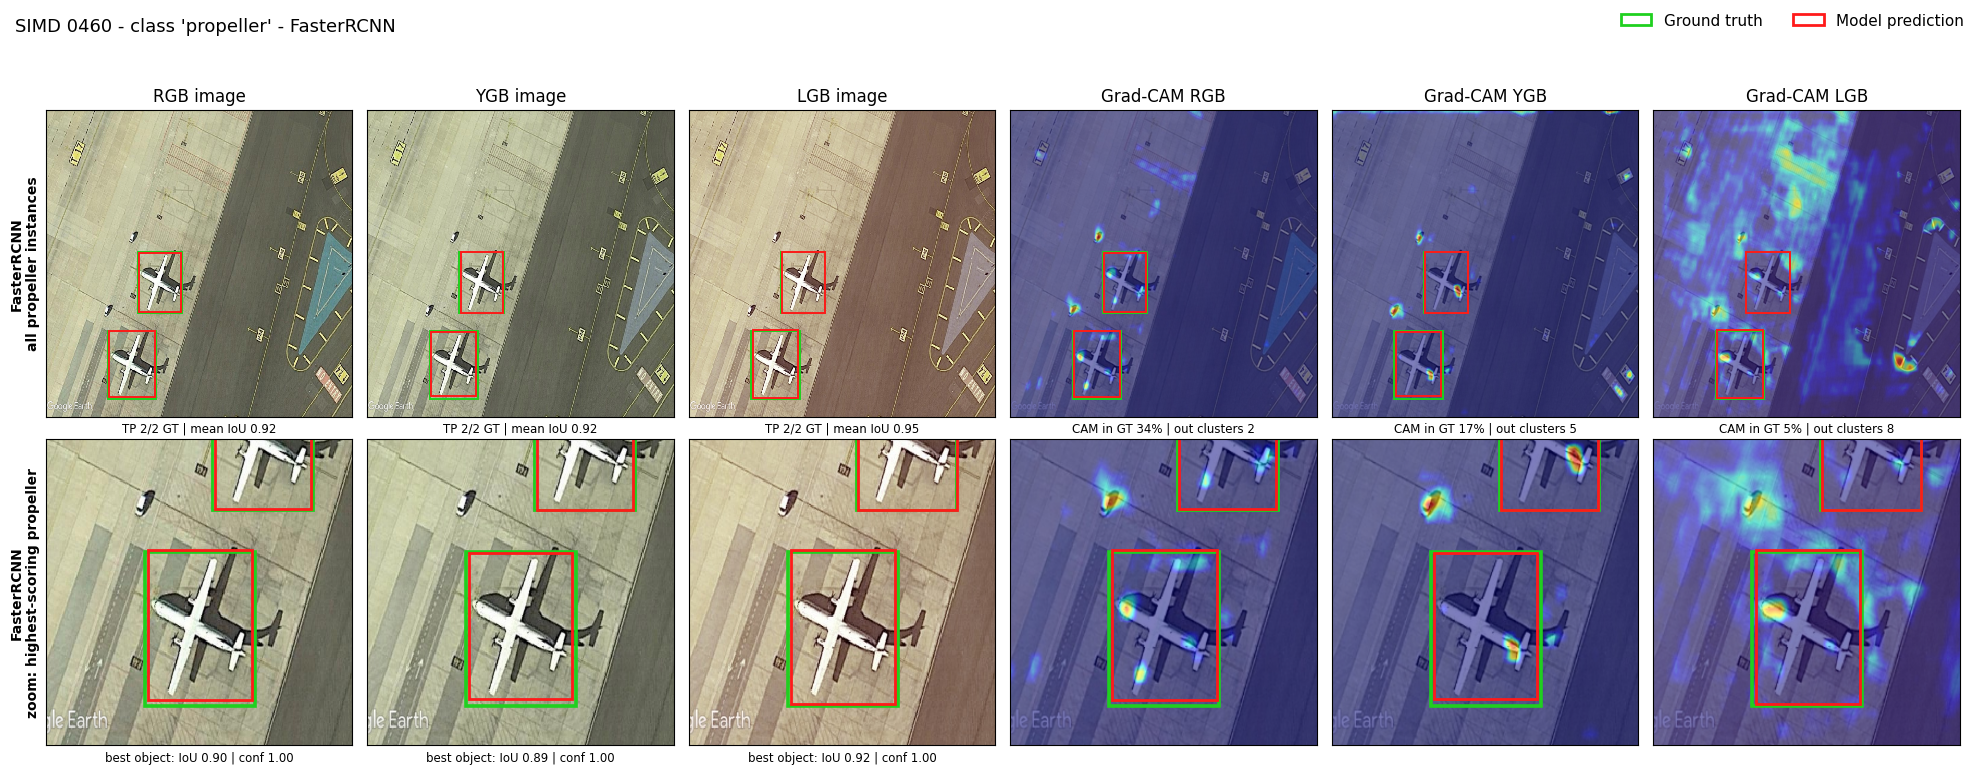

saved: C:\Users\DELL\Desktop\c\GradCAM_SIMD_class_figures\FasterRCNN_0460_propeller_2rows.png


In [21]:
fig, axes = plt.subplots(2, 6, figsize=(6 * 3.3, 2 * 3.5 + 0.8))
draw_model_rows([axes[0], axes[1]], BUNDLE, MODEL_TAG)
fig.legend(handles=[Patch(fill=False, edgecolor=GREEN, label="Ground truth", linewidth=2),
                    Patch(fill=False, edgecolor=RED, label="Model prediction", linewidth=2)],
           loc="upper right", ncol=2, frameon=False, fontsize=11)
fig.suptitle(f"{DATASET_NAME} {IMAGE_STEM} - class '{CLASS_NAME}' - {MODEL_TAG}", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
out = OUTPUT_DIR / f"{MODEL_TAG}_{IMAGE_STEM}_{CLASS_NAME}_2rows.png"
fig.savefig(out, dpi=200, bbox_inches="tight"); plt.show(); print("saved:", out)

## 10. Metrics table

In [22]:
rows = [{"model": MODEL_TAG, "image": IMAGE_STEM, "class": CLASS_NAME, "representation": c, **METRICS[c]} for c in COLORS]
table = pd.DataFrame(rows)
table.to_csv(OUTPUT_DIR / f"{MODEL_TAG}_{IMAGE_STEM}_{CLASS_NAME}_metrics.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
display(table.round(3))

,model,image,class,representation,n_GT,n_pred,TP,precision,recall,mean_IoU,focus_IoU,focus_conf,CAM_in_GT_pct,GT_area_share_pct,enrichment,outside_clusters,weighted_distance_px,GT_brightness,color_variance
0,FasterRCNN,0460,propeller,RGB,2,2,2,1.0,1.0,0.920,0.904,1.0,33.848000,6.386,5.300,2,114.560,158.797,2054.021
1,FasterRCNN,0460,propeller,YGB,2,2,2,1.0,1.0,0.921,0.886,1.0,17.063999,6.386,2.672,5,259.323,158.797,2054.021
2,FasterRCNN,0460,propeller,LGB,2,2,2,1.0,1.0,0.945,0.919,1.0,4.763000,6.386,0.746,8,242.381,158.797,2054.021


## 11. Notes

* This Grad-CAM is **FPN-level Grad-CAM on class logits** (levels 0–3 summed), not the single-layer map used for YOLO. The heat-map resolution therefore differs between detector families; state this in the caption. As always, Grad-CAM shows *where* the supporting features are, not which colour channel contributes, and each CAM is min–max normalised (max = 1), so compare locations, not intensity.
* Predicted boxes use `DET_CONF = 0.5` here (your Faster R-CNN evaluation threshold) versus 0.25 in the YOLO notebooks; change either so that all rows of the final figure use the same threshold if you prefer.
* **Next:** run `Combine_GradCAM_figure_all_models.ipynb`; it will find `FasterRCNN.pkl` next to the YOLO bundles.